In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms


import numpy as np
import matplotlib.pyplot as plt



from PIL import Image, ImageDraw
from google.colab import drive

import os
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
import torchvision.utils as vutils
from torch.utils.data import Subset


try:
  import torchdiff
except ImportError:
  !pip install torchdiff


from torchdiff.sde import SchedulerSDE, ForwardSDE, ReverseSDE, TrainSDE, SampleSDE
from torchdiff.utils import TextEncoder, Metrics, snr_capped_loss, mse_loss, DiffusionNetwork


if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    print('GPU indisponible, CPU à la place.')
    device = torch.device("cpu")



#montage du drive
drive.mount('/content/drive')

IMG_SIZE = 28
SAVE_DIR = "/content/drive/MyDrive/circle_dataset" #répertoire de sauvegarde sur le drive

# Dataset
batch_size = 64
image_size = 28
num_channels = 1
num_classes = 10

# Latent vector
z_dim = 100

# Training
lr = 5e-5
n_epochs = 30
n_critic = 5
clip_value = 0.01

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Test de la méthode SGM sur des images de cercles

## Génération de l'ensemble de données

In [17]:
# fonction créant une base de données de n_samples images de cercles sur fond noir
# dans le repertoire save_dir. Dans save_dir, deux fichiers en format numpy s'y trouvent:
# X.npy (chaque ligne stocke une image) et y.npy (stockant le rayon du cercle de chaque image).
# Le rayon des cercles varie entre r_min et r_max
def generate_dataset(n_samples, save_dir,img_size,r_min=3,r_max=10):
    X = np.zeros((n_samples, img_size, img_size), dtype=np.uint8)
    y = np.zeros(n_samples)

    for i in range(n_samples):
        img = Image.new("L", (img_size, img_size), 0)
        draw = ImageDraw.Draw(img)

        radius = np.random.randint(r_min, r_max)
        x_pos = np.random.randint(radius, img_size - radius)
        y_pos = np.random.randint(radius, img_size - radius)

        bbox = [x_pos-radius, y_pos-radius, x_pos+radius, y_pos+radius]
        draw.ellipse(bbox, outline=255,width=1)

        X[i] = np.array(img)
        y[i] = radius  # label = rayon

    np.save(f"{save_dir}/X.npy", X)
    np.save(f"{save_dir}/y.npy", y)


In [4]:
# À ne pas exécuter si a déjà été exécuté une fois

# création des répertoires SAVE_DIR/train et SAVE_DIR/valid
for split in ["train", "valid"]:
    os.makedirs(f"{SAVE_DIR}/{split}", exist_ok=True)

# génération des datasets de cercles train et valid
train_rep = f"{SAVE_DIR}/train"
valid_rep = f"{SAVE_DIR}/valid"
generate_dataset(8000, train_rep,IMG_SIZE)
generate_dataset(2000, valid_rep,IMG_SIZE)

In [5]:
# facilite la gestion des datasets de cercle
class CircleDataset(torch.utils.data.Dataset):
    def __init__(self, data_dir):
        self.X = np.load(f"{data_dir}/X.npy").astype(np.float32)
        self.y = np.load(f"{data_dir}/y.npy").astype(np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32).unsqueeze(0) / 255.0
        y = "Rayon=" + str(self.y[idx])
        return x, y

In [6]:
# Chargement des images
train_rep = f"{SAVE_DIR}/train"
valid_rep = f"{SAVE_DIR}/valid"
batch_size = 64

c_train_loader = DataLoader(CircleDataset(train_rep), batch_size=batch_size)
c_valid_loader = DataLoader(CircleDataset(valid_rep), batch_size=batch_size)

In [7]:
def show_images(loader,grid_size=(8, 8)):
    x, y = next(iter(loader))
    x = x.squeeze(1)
    fig, axes = plt.subplots(grid_size[0], grid_size[1], figsize=(10,10))
    for i, ax in enumerate(axes.flat):
        ax.imshow(x[i], cmap='gray')
        ax.axis('off')
    plt.show()

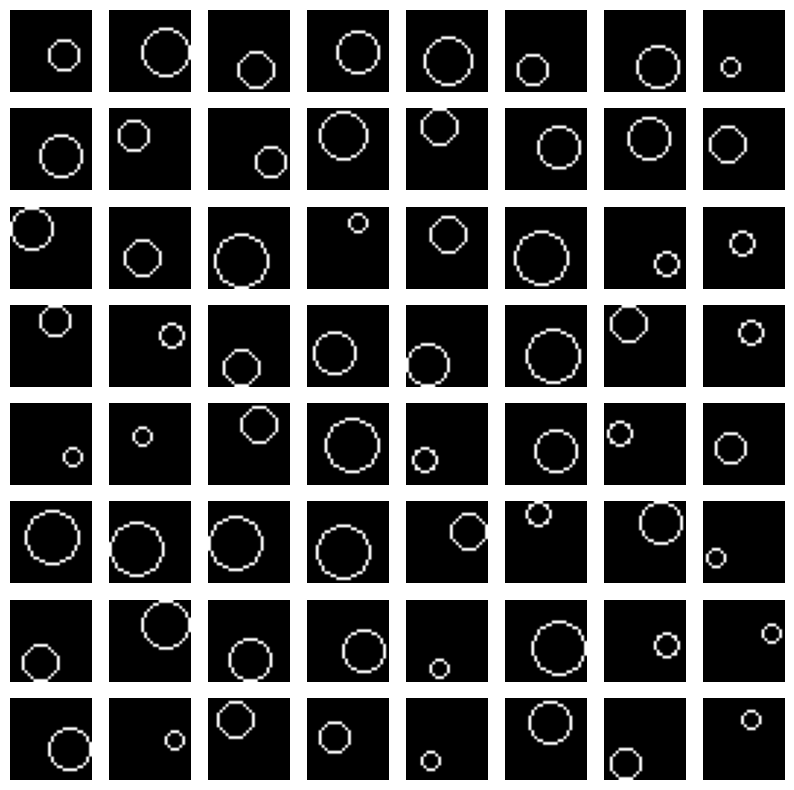

In [8]:
show_images(c_train_loader)

## Entraînement et stockage du réseau prédisant le score

In [9]:
# Generator: 3 blocks + output layer
class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()

        self.net = nn.Sequential(
            # Block 1: [batch, z_dim, 1, 1] -> [batch, 256, 7, 7]
            nn.ConvTranspose2d(z_dim, 256, kernel_size=7, stride=1, padding=0),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # Block 2: [batch, 256, 7, 7] -> [batch, 128, 14, 14]
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # Block 3: [batch, 128, 14, 14] -> [batch, 64, 28, 28]
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # Output layer: [batch, 64, 28, 28] -> [batch, 1, 28, 28]
            nn.ConvTranspose2d(64, 1, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)


  # Critic for WGAN
class Critic(nn.Module):
  def __init__(self):
      super().__init__()

      self.net = nn.Sequential(
          # Input: [batch_size, 1, 28, 28]
          nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),   # -> [64, 14, 14]
          nn.LeakyReLU(0.2, inplace=True),

          nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # -> [128, 7, 7]
          nn.LeakyReLU(0.2, inplace=True),

          nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # -> [256, 3, 3]
          nn.LeakyReLU(0.2, inplace=True),

          nn.Flatten(),
          nn.Linear(256 * 3 * 3, 1)
      )

  def forward(self, x):
      return self.net(x)

# Initialize models
G = Generator(z_dim=z_dim).to(device)
D = Critic().to(device)

print(G)
print(D)

# Optimizers
opt_G = optim.RMSprop(G.parameters(), lr=lr)
opt_D = optim.RMSprop(D.parameters(), lr=lr)

# Noise sampling
def sample_noise(batch_size, z_dim, device):
    return torch.randn(batch_size, z_dim, 1, 1, device=device)

fixed_noise = sample_noise(64, z_dim, device)

def save_generated_images(generator, fixed_noise, device, epoch, save_dir):
    generator.eval()

    with torch.no_grad():
        fake_images = generator(fixed_noise).cpu()

    fake_images = fake_images * 0.5 + 0.5  # dénormalisation

    grid = torchvision.utils.make_grid(fake_images, nrow=8)

    # créer dossier si besoin
    os.makedirs(save_dir, exist_ok=True)

    # sauvegarde
    save_path = os.path.join(save_dir, f"epoch_{epoch}.png")

    plt.figure(figsize=(8, 8))
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.xticks(())
    plt.yticks(())
    plt.suptitle(f"WGAN - Epoch {epoch}")
    plt.savefig(save_path, bbox_inches='tight')
    plt.close()

    generator.train()


Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): Tanh()
  )
)
Critic(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): LeakyReLU(negative_slope=0.

In [10]:
def train_wgan():

    G_losses = []
    D_losses = []

    for epoch in range(n_epochs):

        for batch_idx, (real_images, _) in enumerate(c_train_loader):
            real_images = real_images.to(device)
            current_batch_size = real_images.size(0)

            # -------------------------
            # Train Critic
            # -------------------------
            for _ in range(n_critic):
                z = sample_noise(current_batch_size, z_dim, device)
                fake_images = G(z).detach()

                loss_D = -(D(real_images).mean() - D(fake_images).mean())

                opt_D.zero_grad()
                loss_D.backward()
                opt_D.step()

                # Weight clipping
                for p in D.parameters():
                    p.data.clamp_(-clip_value, clip_value)

            # -------------------------
            # Train Generator
            # -------------------------
            z = sample_noise(current_batch_size, z_dim, device)
            fake_images = G(z)

            loss_G = -D(fake_images).mean()

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            # Save losses
            G_losses.append(loss_G.item())
            D_losses.append(loss_D.item())

        # -------------------------
        # Logging
        # -------------------------
        print(f"Epoch [{epoch+1}/{n_epochs}] | Loss D: {loss_D.item():.4f} | Loss G: {loss_G.item():.4f}")

        # -------------------------
        # Visualization
        # -------------------------
        if (epoch + 1) % 10 == 0:
            save_generated_images(G, fixed_noise, device, epoch+1, save_dir="generated_images")

    return G_losses, D_losses

    # entrainement à faire que si on veut ré-entrainer le modéle
G_losses, D_losses = train_wgan()

Epoch [1/30] | Loss D: -24.9014 | Loss G: 25.3552
Epoch [2/30] | Loss D: -26.4869 | Loss G: 24.2963
Epoch [3/30] | Loss D: -7.6689 | Loss G: 5.9939
Epoch [4/30] | Loss D: -10.6105 | Loss G: 9.9086
Epoch [5/30] | Loss D: -8.2046 | Loss G: 6.1627
Epoch [6/30] | Loss D: -4.9330 | Loss G: 3.2818
Epoch [7/30] | Loss D: -2.7674 | Loss G: 0.5904
Epoch [8/30] | Loss D: -1.7999 | Loss G: -0.6405
Epoch [9/30] | Loss D: -1.8614 | Loss G: 0.0144
Epoch [10/30] | Loss D: -1.3307 | Loss G: -0.3428
Epoch [11/30] | Loss D: -0.9781 | Loss G: -0.1182
Epoch [12/30] | Loss D: -1.3681 | Loss G: -0.0179
Epoch [13/30] | Loss D: -0.6719 | Loss G: -0.9313
Epoch [14/30] | Loss D: -0.3740 | Loss G: -0.6760
Epoch [15/30] | Loss D: -0.4488 | Loss G: -0.8292
Epoch [16/30] | Loss D: -0.5565 | Loss G: -0.3981
Epoch [17/30] | Loss D: -0.3503 | Loss G: -0.4612
Epoch [18/30] | Loss D: -0.3242 | Loss G: -0.6307
Epoch [19/30] | Loss D: -0.4325 | Loss G: -0.4426
Epoch [20/30] | Loss D: -0.2450 | Loss G: -0.5328
Epoch [21/30

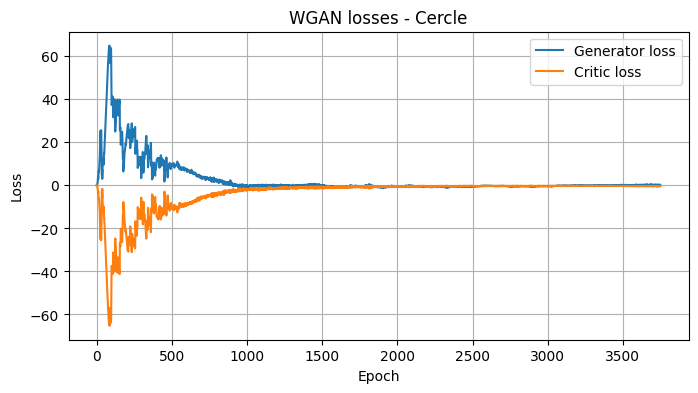

In [11]:
# Plot losses
def plot_losses(G_losses, D_losses, title="Training losses"):
    plt.figure(figsize=(8, 4))
    plt.plot(G_losses, label="Generator loss")
    plt.plot(D_losses, label="Critic loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

#Affichage des pertes
plot_losses(G_losses, D_losses, title="WGAN losses - Cercle")

## Génération d'images

In [12]:
def evaluate_wgan_random(generator, z_dim=100, device=device, n=16, title_prefix="Evaluation"):
    generator.eval()

    real_images, _ = next(iter(c_train_loader))
    real_images = real_images[:n] * 0.5 + 0.5

    cols = 4
    rows = min((n + cols - 1) // cols, n)

    fig, axes = plt.subplots(rows, cols, figsize=(8, 8))
    axes = axes.flat if hasattr(axes, "flat") else [axes]

    for i, ax in enumerate(axes):
        if i < len(real_images):
            ax.imshow(real_images[i].squeeze(), cmap="gray")
        ax.axis("off")
    plt.suptitle(f"{title_prefix} - Real images")
    plt.show()

    with torch.no_grad():
        z = torch.randn(n, z_dim, 1, 1, device=device)
        fake_images = generator(z)

    fake_images = fake_images * 0.5 + 0.5

    fig, axes = plt.subplots(rows, cols, figsize=(8, 8))
    axes = axes.flat if hasattr(axes, "flat") else [axes]

    for i, ax in enumerate(axes):
        if i < len(fake_images):
            ax.imshow(fake_images[i].squeeze().cpu(), cmap="gray")
        ax.axis("off")
    plt.suptitle(f"{title_prefix} - Generated images")
    plt.show()

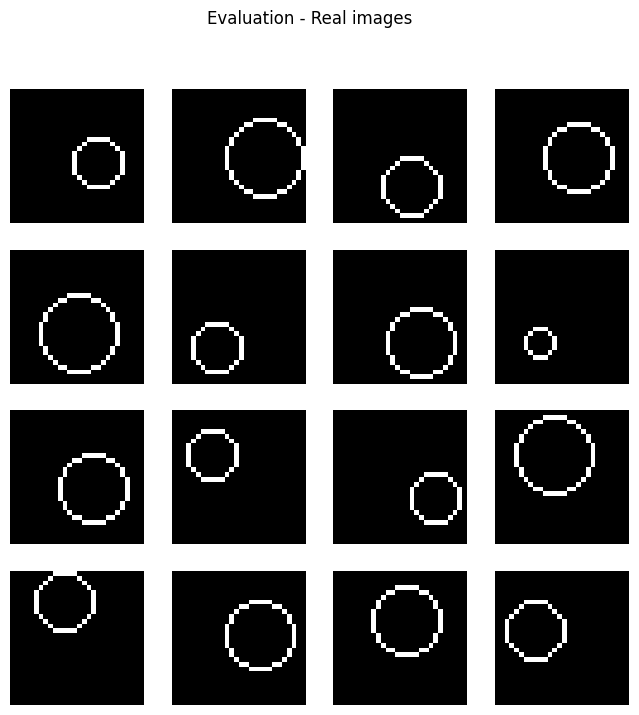

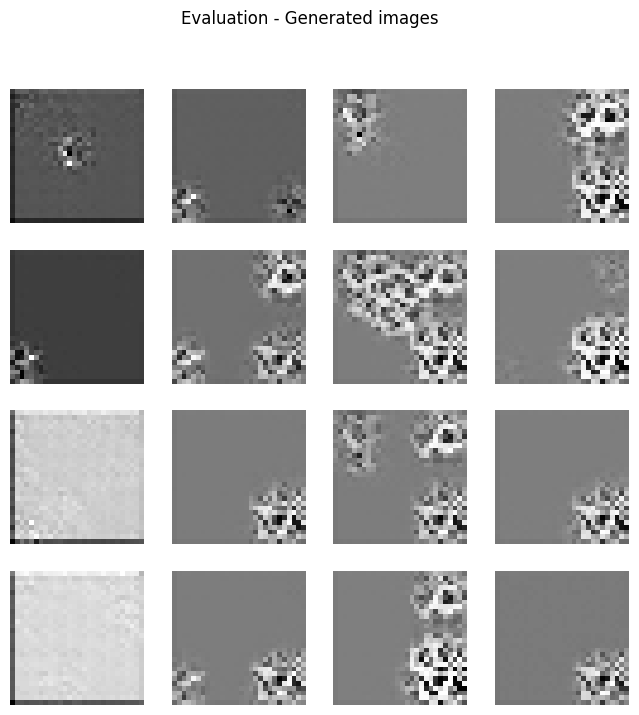

In [13]:
evaluate_wgan_random(G)

In [14]:
def show_saved_images(save_dir):
    images = os.listdir(save_dir)

    plt.figure(figsize=(15, 10))

    for i, img_name in enumerate(images):
        img_path = os.path.join(save_dir, img_name)
        img = Image.open(img_path)

        plt.subplot(1, len(images), i + 1)
        plt.imshow(img)
        plt.title(img_name.replace(".png", ""))
        plt.axis("off")

    plt.show()

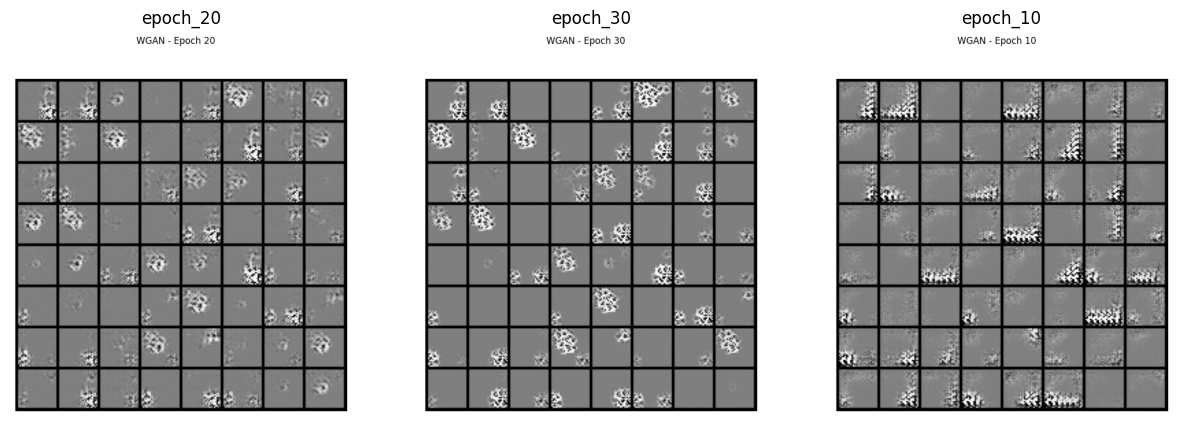

In [15]:

show_saved_images(save_dir="generated_images")